# Relaxing to a static state

![pytdgl logo](https://raw.githubusercontent.com/loganbvh/py-tdgl/main/docs/images/logo-transparent-small.png)

The explicit time step in `pyTDGL` is limited by the covariant Laplacian in the $\psi$ update, which is stable only while `dt` is small compared with the mesh spacing. In a relaxation run only the final state matters, so that limit is where most of the work goes.

Setting `SolverOptions.implicit_laplacian=True` treats that term with linearly implicit Euler instead, solved by a Jacobi-preconditioned BiCGSTAB iteration, so `dt` is no longer capped by the mesh. The scheme stays first order and relaxes to the same static state, which lets it take much larger steps.

In [1]:
# Automatically install tdgl from GitHub only if running in Google Colab
if "google.colab" in str(get_ipython()):
    %pip install --quiet git+https://github.com/loganbvh/py-tdgl.git

%config InlineBackend.figure_formats = {"retina", "png"}

import os

os.environ["OPENBLAS_NUM_THREADS"] = "1"

import matplotlib.pyplot as plt
import numpy as np

import tdgl
from tdgl.geometry import box

## The device

The model is a strip with two terminals and a weak pinning site in the middle. A small current is injected at the source and extracted at the drain, and two probe points measure the phase difference along the strip.

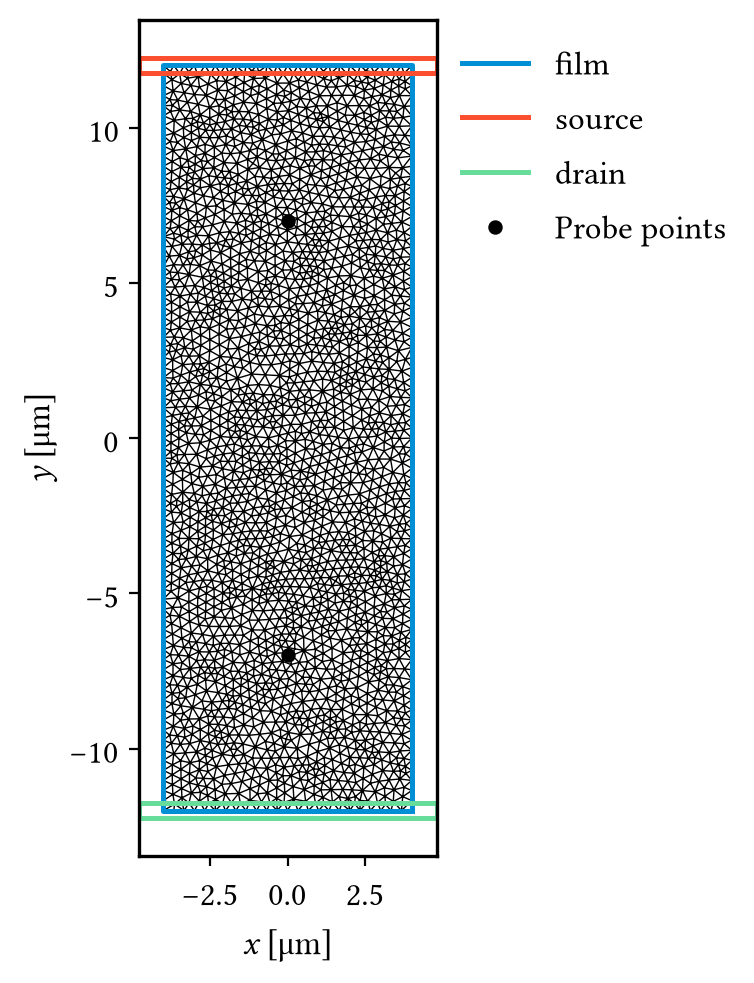

In [2]:
layer = tdgl.Layer(coherence_length=1, london_lambda=2, thickness=0.1, gamma=1)
device = tdgl.Device(
    "strip",
    layer=layer,
    film=tdgl.Polygon("film", points=box(8, 24)),
    terminals=[
        tdgl.Polygon("source", points=box(9.6, 0.5, center=(0, 12))),
        tdgl.Polygon("drain", points=box(9.6, 0.5, center=(0, -12))),
    ],
    probe_points=[(0, -7), (0, 7)],
)
device.make_mesh(max_edge_length=0.5, smooth=50)

fig, ax = device.plot(mesh=True, legend=True)

`relax()` runs the same problem for 150 $\tau$ with whatever solver options it is given.

In [3]:
def disorder(r):
    return -1.0 if (abs(r[0]) <= 1 and abs(r[1]) <= 1) else 1.0


def relax(**opts):
    options = tdgl.SolverOptions(solve_time=150, save_every=10**6, **opts)
    return tdgl.solve(
        device,
        options,
        disorder_epsilon=disorder,
        terminal_currents=dict(source=0.2, drain=-0.2),
    )

## Explicit time stepping

In [4]:
ref = relax()
print(f"explicit: {len(ref.dynamics.dt)} steps")

explicit: 6199 steps


## Implicit Laplacian

The same run with `implicit_laplacian=True` and `dt_max` raised to 1.

In [5]:
imp = relax(implicit_laplacian=True, dt_init=1e-4, dt_max=1.0)
print(f"implicit: {len(imp.dynamics.dt)} steps")

implicit: 520 steps


The explicit limit follows the mesh spacing, so the implicit run needs an order of magnitude fewer steps for the same 150 $\tau$. Both runs reach the same state up to the first order error of the implicit scheme, and the phase difference settles to the same value.

max |psi|^2 difference: 1.1e-04


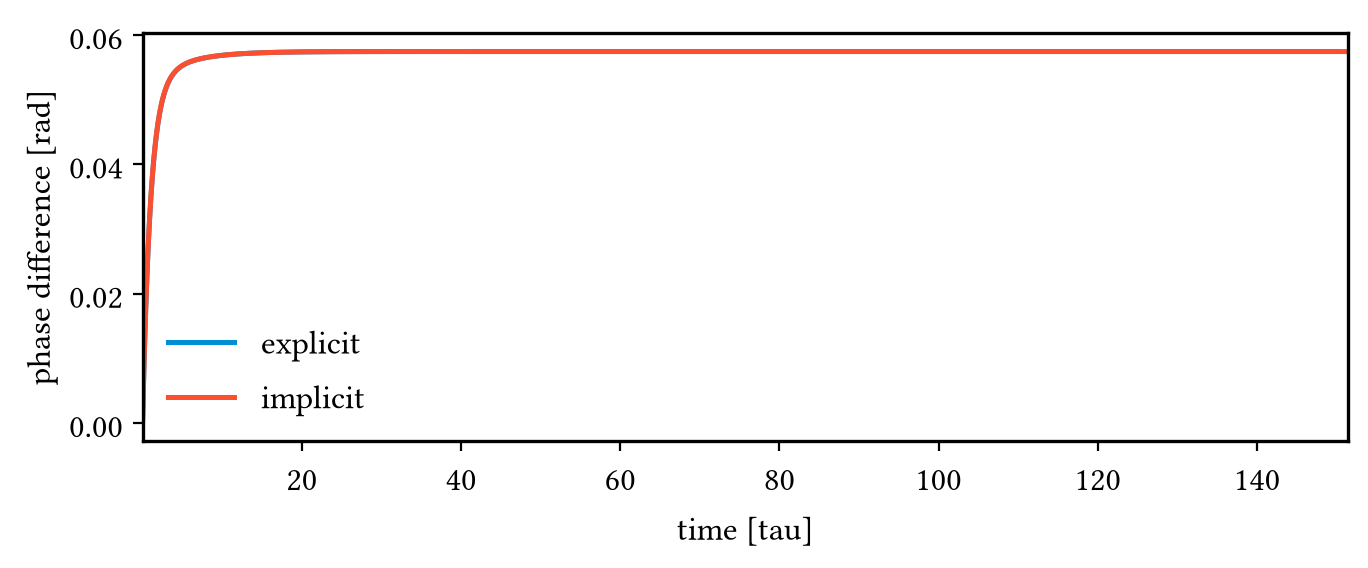

In [6]:
diff = np.abs(np.abs(imp.tdgl_data.psi) ** 2 - np.abs(ref.tdgl_data.psi) ** 2)
print(f"max |psi|^2 difference: {diff.max():.1e}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(ref.dynamics.time, ref.dynamics.phase_difference(0, 1), label="explicit")
ax.plot(imp.dynamics.time, imp.dynamics.phase_difference(0, 1), label="implicit")
ax.set_xlabel("time [tau]")
ax.set_ylabel("phase difference [rad]")
ax.legend();

## When not to use it

An implicit step does more work than an explicit one, since it solves a linear system, so the saving in wall time depends on the mesh and on the machine. It grows as the mesh is refined, because the explicit step limit falls with the mesh spacing while the implicit step count does not.

The scalar potential stays explicit, so `dt_max` above about 1 is unstable even with the implicit Laplacian. The splitting error also grows with `dt` in a dynamic state with a finite voltage or moving vortices, so there keep `dt_max` near 0.02. The option needs the fused CPU kernels, which are the default, and does not work with `gpu=True`.